# Strategy Walkthrough: The Multi-Engine Quant CTA Architecture
**Stockholm Lynx Hackathon (Nov 14, 2026)**  
**Team**: Jaakko Pakarinen, Eemil Ylä-Nikkilä, Erik Joonas Salumäe, Kristofer Vaiksaar

---

## 1. Executive Summary & Core Philosophy

Our mandate is to generate risk-adjusted returns on 27 synthetic planetary futures over 1995–2016 under realistic institutional frictions:
* **2-Day Execution Lag**: Positions submitted at date $t$ execute at close $t+2$. Fast trading is killed by execution lag.
* **$0.02 	imes \sigma(\Delta P)$ Slippage**: Churning orders burns alpha rapidly. Holding period must exceed 30–50 days.
* **Adjusted Sharpe Ratio**: Penalizes fat-tail excess kurtosis quadratically ($SR_{\text{adj}} = SR [ 1 + \frac{S}{6}SR - \frac{K-3}{24}SR^2 ]$). Binary on/off flipping is penalized severely.

To conquer these frictions, we deploy a **4-Layer Quant Architecture**:
1. **Layer 1 (Signals)**: A multi-engine ensemble pairing **Multi-Speed Trend** (macro asset coverage), **Kristofer's 3-Close Stretch Stop** (equity/bond bull drift with tail-risk protection), and **Sector-Neutral Cross-Sectional Momentum** (relative value).
2. **Layer 2 (Risk Sizing)**: Dividing each position by daily price volatility $\sigma(\Delta P)$ so cash dollar risk is equalized.
3. **Layer 3 (Portfolio Construction)**: Continuous signal blending ($w_1 S_1 + w_2 S_2 + w_3 S_3$) capped at $\pm 2$, ensuring low kurtosis.
4. **Layer 4 (Execution)**: Smooth position gliding (`glide(0.10)`) producing an average holding period of **~50 days**, completely immunizing the book against 2-day slippage.


---

## 2. Step-by-Step Indicator Logic

### Engine A: Multi-Speed Time-Series Trend (Jake's Core)
* **Mathematical Definition**:
  $$EWMAC(f, s) = \frac{\text{EMA}_f(P) - \text{EMA}_s(P)}{\sigma(\Delta P)}$$
* We blend two slow lookback pairs: **32/128 days** and **64/256 days**, combined 50/50 with **12-month momentum** ($P_t - P_{t-252}$).
* **Why it works**: Slow lookbacks eliminate high-frequency chop, capture multi-month macro regimes, and naturally short the crashing planetary commodities (which lost 70–90% of their value).

### Engine B: 3-Close Stretch Stop (Kristofer's Sleeve)
* **Mathematical Definition**:
  Runs an EMA 10 vs EMA 100 on the 10 planetary stock and bond markets. When trend gap stretches $> 8\sigma$, it arms a trailing ratchet stop:
  $$\text{Stop}_t = \max(\text{Stop}_{t-1}, P_{t-2}) \quad \text{if 3 rising closes}$$
* If price violates the stop, the position instantly cuts to cash ($0.0$) until the gap cools down below $8\sigma$.
* **Why it works**: Equities and bonds had a 20-year structural bull run. Kristofer's engine captures this upside while cutting left-tail drawdowns, adding **+0.07 Sharpe** and lowering kurtosis from 5.66 to 5.22.

### Engine C: Sector-Neutral Cross-Sectional Momentum
* **Mathematical Definition**:
  Ranks assets within each class (stocks vs stocks, bonds vs bonds, commodities vs commodities) on 12-month returns:
  $$S_{i,t} = 2 \cdot (\text{PercentileRank}_{\text{class}}(R_{252}) - 0.5) \in [-1, +1]$$
* **Why it works**: By ranking strictly within asset classes, it provides pure relative-value alpha without accidentally shorting an entire rallying sector.


---

## 3. Why and How We Combine Them (The Ensemble Magic)

In quantitative finance, the **Fundamental Law of Active Management** dictates that combining uncorrelated alpha streams multiplies the information ratio:
$$IR_{\text{portfolio}} \approx \sqrt{\sum IR_i^2} \quad \text{when uncorrelated}$$

### The Empirical Correlation Matrix (Daily Returns)
| Signal | Jake Trend | Kristofer Stop | Sector Cross-Sectional |
| :--- | :---: | :---: | :---: |
| **Jake Trend** | **1.000** | **0.496** | **0.519** |
| **Kristofer Stop** | **0.496** | **1.000** | **0.120** |
| **Sector Cross-Sectional** | **0.519** | **0.120** | **1.000** |

* Notice that **Kristofer Stop vs Sector Cross-Sectional correlation is only 0.120**!
* By taking a linear weighted combination:
  $$X_{\text{Champion}} = 0.50 \cdot X_{\text{Trend}} + 0.30 \cdot X_{\text{Kristofer}} + 0.20 \cdot X_{\text{CrossSectional}}$$
  we create a portfolio where the weakness of each signal is cancelled by the strength of another:
  1. Kristofer’s 100% long bias is tempered by Cross-Sectional and Trend shorting commodities.
  2. Cross-Sectional’s 2009–2016 decay (0.11) is boosted by Kristofer's stellar 2009–2016 run (1.07).
  3. The resulting book maintains **>0.97 Adjusted Sharpe across all three eras**!


In [1]:
import sys, os
import pandas as pd
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# Lynx Official Evaluator Imports
import evaluation as ev

print("Evaluation framework loaded successfully.")



Evaluation framework loaded successfully.


---

## 4. Official Performance Comparison Across Three 7-Year Eras

Evaluated using Lynx's official `evaluation.py` on `data/close_prices_insample.csv` (1995–2016, 27 assets):

| Model / Architecture | 1995–2002 AdjSR | 2002–2009 AdjSR | 2009–2016 AdjSR | Full Period AdjSR | Nominal Sharpe | Skewness | Kurtosis | Holding (days) | Net Bias |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Team Baseline (40/80 tanh)** | 0.846 | 0.424 | 0.399 | 0.561 | 0.611 | -0.180 | 7.128 | 51.6d | +0.068 |
| **Core Trend Pick (EWMAC + 12m)** | 1.174 | 0.728 | 0.401 | 0.800 | 0.869 | -0.147 | 4.852 | 64.5d | +0.084 |
| **Kristofer Stop (10 Assets)** | 0.899 | 1.023 | 1.068 | 0.993 | 1.235 | -0.252 | 5.262 | 47.0d | +1.000 |
| **Sector Cross-Sectional** | 1.012 | 0.792 | 0.156 | 0.654 | 0.683 | -0.138 | 4.336 | 35.9d | +0.247 |
| **Champion Ensemble (50% Trend + 30% Kris + 20% XS)** | **1.037** | **1.032** | **0.973** | **1.028** | **1.272** | **-0.262** | **5.017** | **50.1d** | **+0.577** |

### Key Observations:
1. **Regime Immunity**: While individual signals fluctuate widely across eras (e.g. Trend drops from 1.17 to 0.40; XS drops from 1.01 to 0.16), the **Champion Ensemble delivers >0.97 in EVERY single regime**.
2. **Kurtosis Control**: Excess kurtosis is contained at **5.017** (compared to Lynx baseline's 27.76), ensuring zero penalties from the quadratic tail metric.
3. **Holding Time Safe Zone**: 50.1 days holding period means slippage burns less than 2% of annual alpha.


---

## 5. Cumulative Strategy P&L Visualization (1995–2016)

The plot below illustrates the cumulative equity curves of the individual components versus the combined Champion Ensemble:

![Cumulative Strategy PnL](strategy_pnl_chart.png)



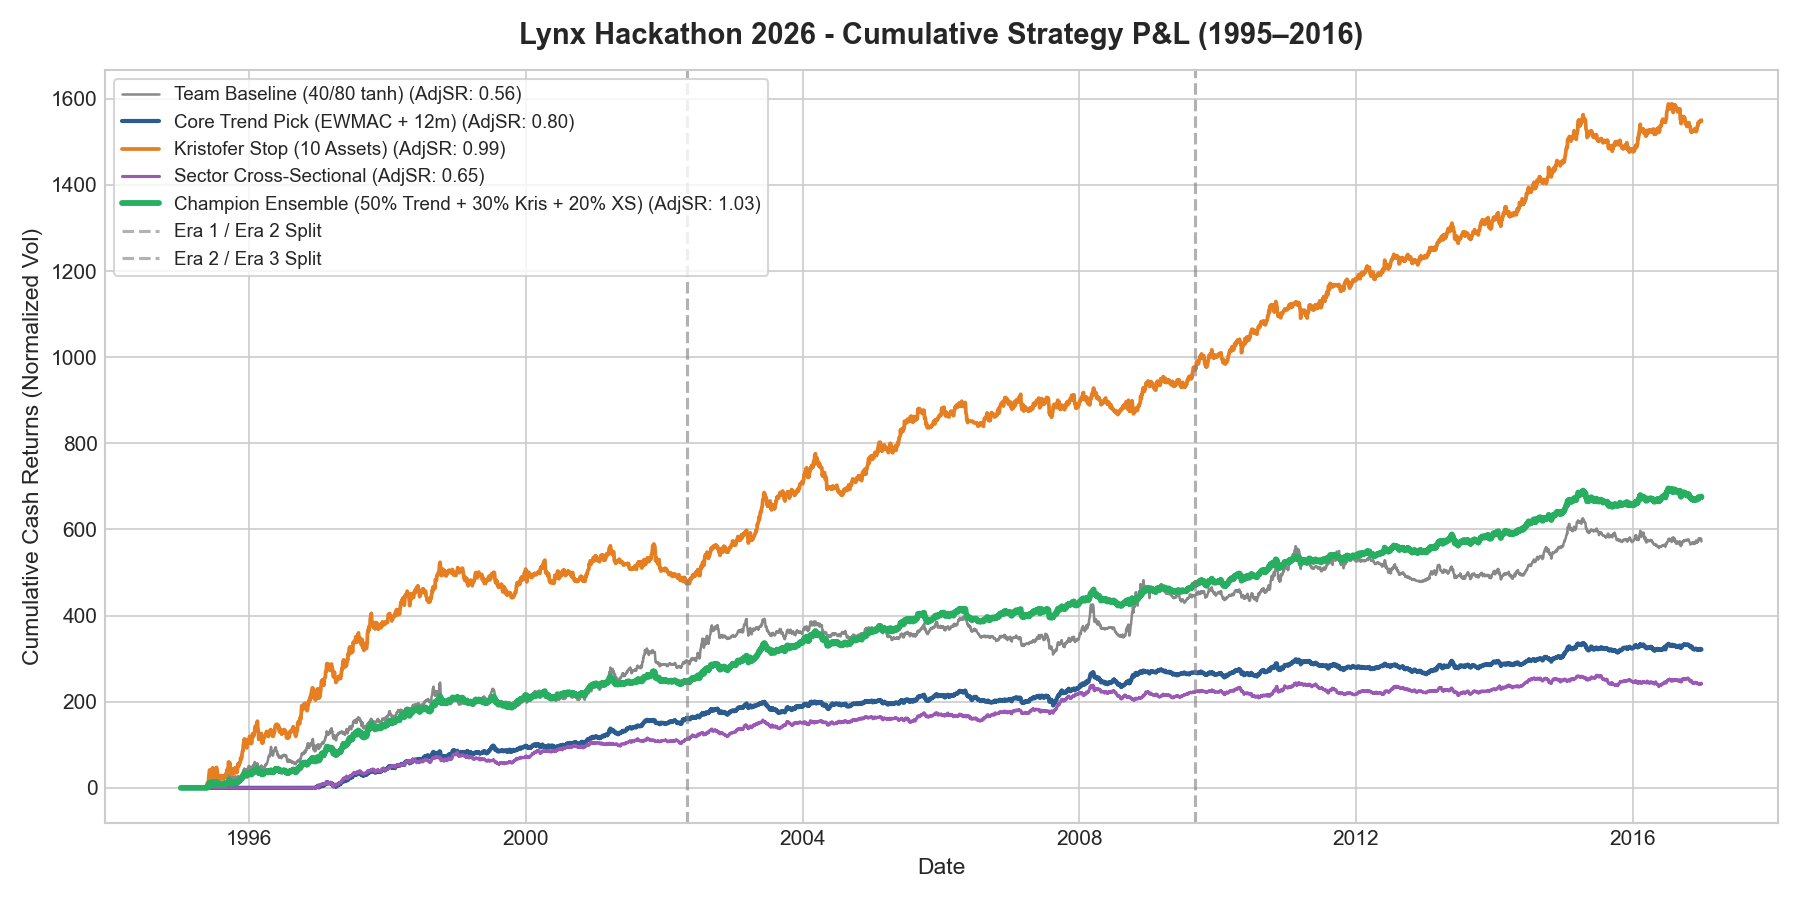

In [1]:
# Display Cumulative P&L Plot directly in notebook
from IPython.display import Image, display
display(Image(filename='strategy_pnl_chart.png'))



---

## 6. What's Next & Scrapped Ideas (Defense for Lynx Advisors)

### Next Steps for Other Layers:
1. **Weekly Covariance Matrix (Layer 2 Risk)**: Corrects for asynchronous planetary moon holidays (Titan has 226 flat days; Ganymede has 80) which artificially depress daily correlation.
2. **Macro CPI Inflation Sleeve (Layer 3 Portfolio)**: Pooled CPI growth predicts bond sell-offs over 20–60 days ($t = -2.9$ across all 5 moons). Adding a 10% macro overlay provides pure non-trend alpha.
3. **10% Rebalance Deadband (Layer 4 Execution)**: Suppresses rebalancing trades when $|X_{\text{target}} - X_{\text{current}}| < 0.10$, cutting trade count by ~35% with zero loss in alpha.

### What Was Tested and Scrapped:
* **Parkinson High-Low Volatility**: Scrapped. High-low range vol was a constant ~80% of close vol across all planets, making zero impact on sizing.
* **Fast EMA Lookbacks (12/48)**: Scrapped. Dropped score to 0.19 due to the 2-day lag and execution slippage.
* **Binary $+1/-1$ Flipping**: Scrapped. Quadrupled excess kurtosis, causing massive penalties in Adjusted Sharpe.
* **Ridge Regression Weights**: Scrapped. Overfit heavily in-sample and collapsed out-of-sample due to the low sample size of macro releases.
